# Naive Bayes (Gaussian)

Run `00_prepare_data.ipynb` first. Same train/test split as all other models (seed 42).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path("..").resolve() / "src"))

import pandas as pd
from sklearn.metrics import classification_report

from common import CLASS_NAMES, SEED, plot_confusion_matrix, train_and_evaluate

## Model

### Why Gaussian Naive Bayes
- Our numeric features are scaled with `PowerTransformer`, so many values are negative.
- Multinomial Naive Bayes only works with non-negative values (like counts), so it cannot be used here.
- Gaussian Naive Bayes works with continuous values, so we use it.
- We use the default settings, because Naive Bayes has no main parameter like `k` in KNN.

In [2]:
from sklearn.naive_bayes import GaussianNB

model = GaussianNB()

## Train & evaluate
Saves `model/naive_bayes.joblib` and updates `results/metrics.csv`.

In [3]:
result = train_and_evaluate("naive_bayes", model)
pd.DataFrame([result["metrics"]], index=["Naive Bayes (Gaussian)"])

,Accuracy,AUC,Precision,Recall,F1,MCC
Naive Bayes (Gaussian),0.8697,0.8532,0.6,0.5631,0.581,0.5043


## Confusion matrix

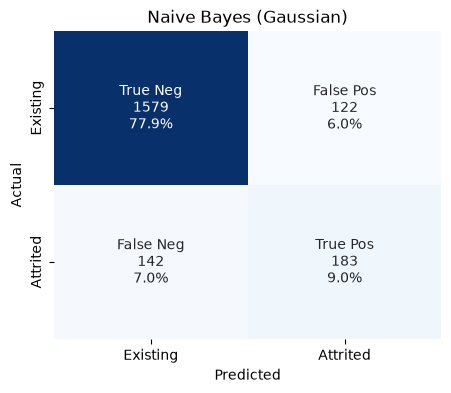

In [4]:
plot_confusion_matrix(result["y_test"], result["y_pred"], title="Naive Bayes (Gaussian)")

## Classification report

In [5]:
print(classification_report(result["y_test"], result["y_pred"], target_names=CLASS_NAMES, digits=4))

              precision    recall  f1-score   support

    Existing     0.9175    0.9283    0.9229      1701
    Attrited     0.6000    0.5631    0.5810       325

    accuracy                         0.8697      2026
   macro avg     0.7587    0.7457    0.7519      2026
weighted avg     0.8666    0.8697    0.8680      2026



## Observations
- Naive Bayes has the lowest scores among all models so far (accuracy 0.870, F1 0.581, MCC 0.504).
- Recall for churned customers is 0.563, same as KNN, but precision is only 0.600. So 4 out of 10 churn predictions are wrong.
- Naive Bayes assumes all features are independent. In this data many features are related (for example, transaction amount and transaction count), which is likely why it performs worse.